# **KNN Regression on the Concrete Dataset**
Target: `strength` (concrete compressive strength, MPa)

**KNN (K-Nearest Neighbors) Regressor:** to predict a new sample, it finds the `k` closest samples in the training data and averages their strength.

Hyperparameters tuned with `GridSearchCV` (5-fold, stratified):
- `n_neighbors` : how many neighbors (k)
- `weights` : `uniform` (all neighbors equal) or `distance` (closer neighbors count more)
- `p` : distance type (1 = Manhattan, 2 = Euclidean)

> KNN works on distances, so features **must be scaled**. `StandardScaler` is inside the Pipeline.

### Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset and Stratified Split
High-strength samples are rare, so we split on strength ranges to keep the same ratio in train and test.

In [3]:
df = pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

(804, 8) (201, 8)


### KNN Pipeline and Hyperparameter Grid

In [4]:
knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor())
])

param_grid = {
    'model__n_neighbors': list(range(1, 31)),
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
}

### GridSearchCV

In [5]:
%%time
grid = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
grid.fit(x_train, y_train)

print('Best Params      :', grid.best_params_)
print('Best CV R2 score :', round(grid.best_score_, 4))

Best Params      : {'model__n_neighbors': 4, 'model__p': 2, 'model__weights': 'distance'}
Best CV R2 score : 0.8704
CPU times: total: 3.28 s
Wall time: 21.8 s


### Test Set Evaluation

In [6]:
best_knn = grid.best_estimator_
y_pred = best_knn.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE  :', round(mae, 4))
print('MSE  :', round(mse, 4))
print('RMSE :', round(rmse, 4))
print('R2   :', round(r2, 4))

MAE  : 3.6503
MSE  : 27.055
RMSE : 5.2014
R2   : 0.899


### Visualization

C:\Users\adnan\AppData\Local\Temp\ipykernel_17072\3074179604.py:21: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.show()


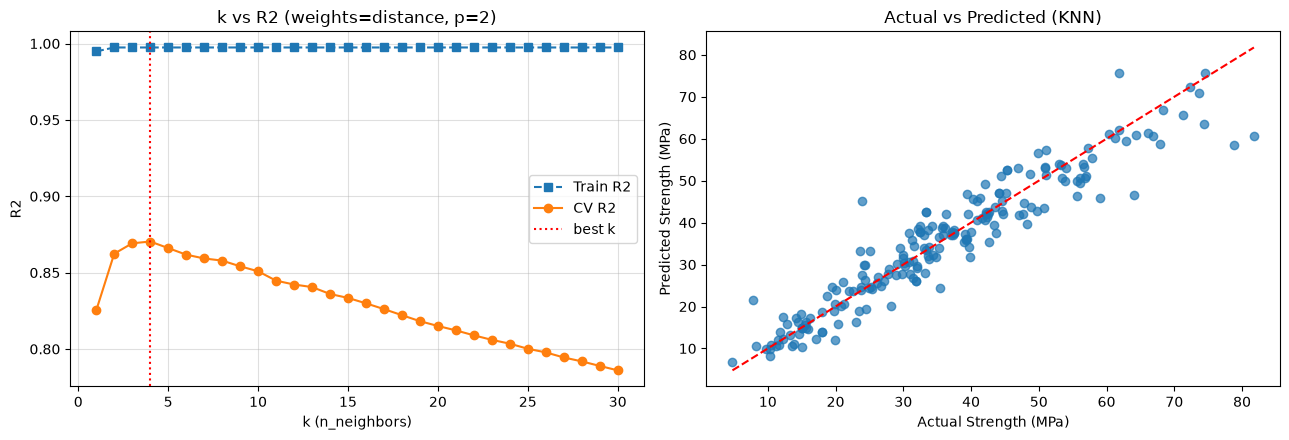

In [7]:
#k vs R2 (best weights / p). Small k = overfit, large k = underfit
res = pd.DataFrame(grid.cv_results_)
best_w, best_p = grid.best_params_['model__weights'], grid.best_params_['model__p']
r = res[(res['param_model__weights'] == best_w) & (res['param_model__p'] == best_p)].sort_values('param_model__n_neighbors')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(r['param_model__n_neighbors'], r['mean_train_score'], 's--', label='Train R2')
ax[0].plot(r['param_model__n_neighbors'], r['mean_test_score'], 'o-', label='CV R2')
ax[0].axvline(grid.best_params_['model__n_neighbors'], color='r', ls=':', label='best k')
ax[0].set_xlabel('k (n_neighbors)'); ax[0].set_ylabel('R2')
ax[0].set_title(f'k vs R2 (weights={best_w}, p={best_p})')
ax[0].legend(); ax[0].grid(alpha=0.4)

#Actual vs Predicted
ax[1].scatter(y_test, y_pred, alpha=0.7)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[1].set_xlabel('Actual Strength (MPa)'); ax[1].set_ylabel('Predicted Strength (MPa)')
ax[1].set_title('Actual vs Predicted (KNN)')

plt.tight_layout(); plt.show()

### Save the Model (.pkl)
Best KNN is trained once more on all data, then saved with `joblib`.

In [8]:
from sklearn.base import clone

final_knn = clone(best_knn)
final_knn.fit(x, y)

joblib.dump(final_knn, 'knn_concrete_model.pkl')
print('Saved: knn_concrete_model.pkl')

Saved: knn_concrete_model.pkl


### Load and Predict
These 5 rows were also used to train the final model, so KNN (`weights=distance`) predicts them almost exactly. This cell only checks that the saved file loads and works. The honest accuracy is the **Test Set Evaluation** above (trained without the test rows).

In [9]:
model = joblib.load('knn_concrete_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [21.97 15.07 18.03 30.23 68.3 ]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### Download (Google Colab only)

In [ ]:
try:
    from google.colab import files
    files.download('knn_concrete_model.pkl')
except ImportError:
    print('Not Colab - file is saved in the notebook folder.')

Not Colab - file is saved in the notebook folder.
